<a href="https://colab.research.google.com/github/ItsAdarsh008/microbots/blob/main/notebooks/runs/hard_run1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Microbots: a GNN + GRU policy that knows when it's needed, and when to go home

With 3× or 5× more bots than a shape needs, two things should happen:

- **(a) Only the bots that are needed go to work.** The rest stay where they are.
- **(b) When the shape is finished, the spares go home** to the pad where they started, instead of sitting in a heap on top of the structure.

Neither can be decided by one bot alone: whether you're one of the bots nearest the work, and whether the shape is finished out of sight, are facts about the whole swarm. The hand-written rules (the **teacher**) cheat and look at the whole grid. The network has to work it out from its neighbours:

- **GNN:** every step, each bot sends messages to the bots touching it and combines what it hears (3 rounds per step).
- **GRU:** each bot carries a memory from step to step, so news like "the work is that way" or "everything's built, go home" can keep travelling.

Each bot sees its own 5×5×5 block, whether it's locked in or parked, the relayed "how far to the work" signal bots pass to each other, and (by default) a compass pointing at the nearest open cell, or home once the shape is built. What it still has to work out from its neighbours: **am I one of the bots that's needed**, and **is the build finished**. Every bot runs the same network. It learns by copying the teacher, then DAgger (the network drives, the teacher labels).

A first try with no signal and no compass (fewer inputs, more to learn) failed: driving on its own, the swarm stalled. See `linking/EXPERIMENTS.md`, section 9.

Code: [`linking/learn/gnn_gru.py`](https://github.com/ItsAdarsh008/microbots/blob/main/linking/learn/gnn_gru.py) · the teacher's rules: `env.plan()` in [`env.py`](https://github.com/ItsAdarsh008/microbots/blob/main/linking/learn/env.py).

**Before you start:** Runtime → Change runtime type → **T4 GPU**. Recording and testing run the simulation on the CPU either way (a few seconds per build); the GPU is for training.

In [1]:
!nvidia-smi -L || echo "No GPU: Runtime > Change runtime type > T4 GPU"
!git clone -q --depth 1 https://github.com/ItsAdarsh008/microbots
%cd microbots/linking/learn
!pip -q install scipy
import jax
print("JAX", jax.__version__, "on", jax.devices())

GPU 0: Tesla T4 (UUID: GPU-894bfeb1-5962-1392-69d4-64b38b2df1a4)
fatal: destination path 'microbots' already exists and is not an empty directory.
/content/microbots/linking/learn
JAX 0.11.1 on [CudaDevice(id=0)]


## 1. Settings

In [2]:
import time, numpy as np, jax, jax.numpy as jnp
import gnn_gru as G

# Run twice. First with EASY = True: plain building, normal number of bots, every bot works,
# no trip home. It's quick and shows whether the network learns at all (it should build
# the wall and the arch). Then set EASY = False for the real thing.
EASY = False

MULT = 1 if EASY else 3      # times the usual number of bots (3 or 5 for the real run)
SEEDS = 12        # teacher builds per shape (wall and arch)
EPOCHS = 40
DAGGER = 3        # rounds of "the network drives, the teacher labels"
MEMORY = True     # False = wipe each bot's memory every step, for comparison
G.USE_SIGNAL = True     # the relayed "how far to the work" hop count, passed bot to bot (local)
G.USE_COMPASS = True    # direction to the nearest open cell / home: a shortcut, but it makes training much easier
G.THRIFTY, G.PARK = (False, False) if EASY else ("rank", True)
print("bots padded to", G.configure(MULT))


bots padded to 576


## 2. Record the teacher

Each build: the teacher builds the **wall** (`sheet`) or the **arch**, with only the bots nearest the work moving, then sends the spares home. At every step we save, for every bot: what it sees, who it can hear (the bots in the 26 cells touching it), its legal moves, and the teacher's move ("stay" for bots that aren't needed).

In [3]:
builds = []
t0 = time.time()
for shape in ["sheet", "arch"]:
    for seed in range(SEEDS):
        rec, st = G.rollout(shape, seed, MULT)
        builds.append(rec)
        print(f"{shape:5s} seed {seed:2d}: built in {st['built_in']}, {st['spares_that_moved']}/{st['spares']} spares moved, home in {st['home_in']}")
print(f"{len(builds)} builds in {time.time() - t0:.0f}s")

sheet seed  0: built in 51, 49/198 spares moved, home in None
sheet seed  1: built in 47, 48/198 spares moved, home in None
sheet seed  2: built in 44, 48/198 spares moved, home in None
sheet seed  3: built in 46, 48/198 spares moved, home in 58
sheet seed  4: built in 47, 48/198 spares moved, home in 26
sheet seed  5: built in 48, 46/198 spares moved, home in None
sheet seed  6: built in 53, 49/198 spares moved, home in None
sheet seed  7: built in 49, 51/198 spares moved, home in 27
sheet seed  8: built in 47, 46/198 spares moved, home in 44
sheet seed  9: built in 47, 49/198 spares moved, home in 86
sheet seed 10: built in 50, 46/198 spares moved, home in None
sheet seed 11: built in 48, 48/198 spares moved, home in None
arch  seed  0: built in 84, 114/324 spares moved, home in None
arch  seed  1: built in 77, 111/324 spares moved, home in None
arch  seed  2: built in 85, 108/324 spares moved, home in None
arch  seed  3: built in 80, 112/324 spares moved, home in None
arch  seed  4:

## 3. The network

Encoder (252 inputs → 64) → 3 rounds of message passing between touching bots → GRU memory → 19 move scores (stay, 6 slides, 12 flips). Illegal moves are masked out, and a safety check underneath means no move can ever drop a bot, whatever the network picks.

In [4]:
params = G.init(jax.random.PRNGKey(0))
opt = G.adam_init(params)
log = {"loss": [], "epoch_end": [], "agree": [], "stage": []}
print(f"{G.count(params):,} weights")

109,844 weights


## 4. Train by imitation

4 builds at a time, 32 steps at a time, with each bot's memory carried through (truncated backpropagation through time). The last number on each line is how often it correctly stays put when the teacher would: that's behaviour (a).

In [5]:
t0 = time.time()
params, opt = G.train(params, opt, builds, EPOCHS, MEMORY, log)
print(f"{time.time() - t0:.0f}s")

  141,895 decisions where the teacher moves the bot, 419,997 where it stays (weights: move 1.98, stay 0.67)
  imitation epoch   1  loss 1.955  |  moves when it should 73%, stays when it should 56%  |  same move as the teacher 22%
  imitation epoch   2  loss 1.670  |  moves when it should 75%, stays when it should 57%  |  same move as the teacher 22%
  imitation epoch   3  loss 1.453  |  moves when it should 71%, stays when it should 81%  |  same move as the teacher 30%
  imitation epoch   4  loss 1.362  |  moves when it should 77%, stays when it should 77%  |  same move as the teacher 34%
  imitation epoch   5  loss 1.400  |  moves when it should 72%, stays when it should 72%  |  same move as the teacher 34%
  imitation epoch   6  loss 1.347  |  moves when it should 74%, stays when it should 79%  |  same move as the teacher 39%
  imitation epoch   7  loss 1.296  |  moves when it should 85%, stays when it should 78%  |  same move as the teacher 43%
  imitation epoch   8  loss 1.229  |  

## 5. DAgger: let the network drive

In [6]:
for r in range(DAGGER):
    for shape in ["sheet", "arch"]:
        for seed in range(1000 + 10 * r, 1000 + 10 * r + SEEDS // 2):
            rec, st = G.rollout(shape, seed, MULT, G.Driver(params, MEMORY, seed))
            builds.append(rec)
            print(f"round {r + 1} {shape:5s} seed {seed}: built in {st['built_in']}, home in {st['home_in']}")
    params, opt = G.train(params, opt, builds, EPOCHS // 4, MEMORY, log, stage=f"dagger {r + 1}")

round 1 sheet seed 1000: built in 57, home in None
round 1 sheet seed 1001: built in 77, home in None
round 1 sheet seed 1002: built in 88, home in None
round 1 sheet seed 1003: built in 101, home in None
round 1 sheet seed 1004: built in 105, home in None
round 1 sheet seed 1005: built in 68, home in None
round 1 arch  seed 1000: built in None, home in None
round 1 arch  seed 1001: built in None, home in None
round 1 arch  seed 1002: built in None, home in None
round 1 arch  seed 1003: built in None, home in None
round 1 arch  seed 1004: built in None, home in None
round 1 arch  seed 1005: built in None, home in None
  473,129 decisions where the teacher moves the bot, 723,648 where it stays (weights: move 1.26, stay 0.83)
  dagger 1  epoch  41  loss 1.345  |  moves when it should 66%, stays when it should 76%  |  same move as the teacher 47%
  dagger 1  epoch  42  loss 1.270  |  moves when it should 77%, stays when it should 72%  |  same move as the teacher 50%
  dagger 1  epoch  43 

## 6. The training curve

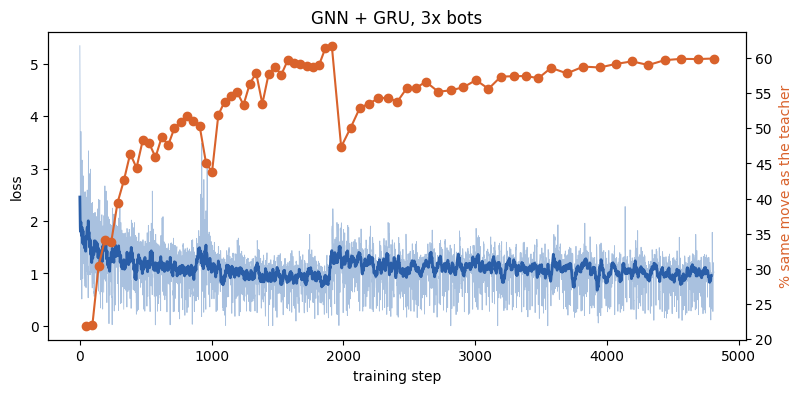

In [7]:
import matplotlib.pyplot as plt
loss = np.array(log["loss"])
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(loss, color="#a9c1df", lw=0.6)
ax.plot(np.convolve(loss, np.ones(20) / 20, mode="valid"), color="#2a5ea8", lw=2)
ax.set_xlabel("training step"); ax.set_ylabel("loss")
ax2 = ax.twinx(); ax2.plot(np.array(log["epoch_end"]), np.array(log["agree"]) * 100, "o-", color="#d9622b")
ax2.set_ylabel("% same move as the teacher", color="#d9622b")
plt.title(f"GNN + GRU, {MULT}x bots"); plt.show()

## 7. Test it against the teacher

Unseen seeds; the **tower** was never trained on. `built_in` is the number of steps to finish the shape (`NaN` / `None` = didn't finish), and `count` is how many builds it was averaged over.

- **EASY = True:** the network should finish the wall and the arch (the teacher takes ~60 and ~130 steps). If it doesn't, stop here and send me the printout.
- **EASY = False:** also look at **spares_that_moved** (lower is better: that's (a)) and **home_in / not_home** (that's (b)).


In [8]:
import pandas as pd
rows = G.evaluate(params, MEMORY, MULT, seeds=range(100, 103))
rows += G.evaluate(params, MEMORY, MULT, seeds=range(100, 103), who="teacher")
df = pd.DataFrame(rows)
cols = ["built_in", "spares_that_moved", "spares", "home_in", "not_home"] if not EASY else ["built_in"]
df.groupby(["who", "shape"])[cols].agg(["mean", "count"]).round(1)


  network  sheet  seed 100: built in 54, 194/198 spares moved, home in 139 (0 not home)
  network  sheet  seed 101: built in 46, 193/198 spares moved, home in None (1 not home)
  network  sheet  seed 102: built in 50, 192/198 spares moved, home in None (1 not home)
  network  arch   seed 100: built in 81, 323/324 spares moved, home in 82 (0 not home)
  network  arch   seed 101: built in 84, 321/324 spares moved, home in None (3 not home)
  network  arch   seed 102: built in 82, 320/324 spares moved, home in 141 (0 not home)
  network  tower  seed 100: built in 64, 356/356 spares moved, home in None (11 not home)
  network  tower  seed 101: built in 64, 353/356 spares moved, home in None (9 not home)
  network  tower  seed 102: built in 67, 351/356 spares moved, home in None (13 not home)
  teacher  sheet  seed 100: built in 41, 46/198 spares moved, home in 24 (0 not home)
  teacher  sheet  seed 101: built in 45, 48/198 spares moved, home in None (1 not home)
  teacher  sheet  seed 102:

built_in       spares_that_moved       spares       home_in  \
                  mean count              mean count   mean count    mean   
who     shape                                                               
network arch      82.3     3             321.3     3  324.0     3   111.5   
        sheet     50.0     3             193.0     3  198.0     3   139.0   
        tower     65.0     3             353.3     3  356.0     3     NaN   
teacher arch      78.0     3             113.3     3  324.0     3     NaN   
        sheet     46.0     3              47.0     3  198.0     3    24.0   
        tower     56.3     3              96.7     3  356.0     3   110.0   

                    not_home        
              count     mean count  
who     shape                       
network arch      2      1.0     3  
        sheet     1      0.7     3  
        tower     0     11.0     3  
teacher arch      0      5.3     3  
        sheet     1      1.0     3  
        tower     1      2.0     3

## 8. Try it without memory

Set `MEMORY = False` in section 1 and run everything again. If the bots really use their memory to pass on "is the work over there" and "is everything built", this version should be worse at (a) and especially (b).

## 9. Keep the weights

In [9]:
import pickle
name = f"gnn_{'gru' if MEMORY else 'nomem'}_x{MULT}{'_easy' if EASY else ''}.pkl"
pickle.dump({"params": jax.tree_util.tree_map(np.asarray, params), "memory": MEMORY, "mult": MULT,
             "signal": G.USE_SIGNAL, "compass": G.USE_COMPASS}, open(name, "wb"))
try:
    from google.colab import files; files.download(name)
except ImportError:
    print("saved", name)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>